У коллаборации подготовлены тетрадки, где показано как обрабатывать данные

[DR4_DR5_Notebooks](https://github.com/ACTCollaboration/DR4_DR5_Notebooks) - здесь лежат туториалы по тому как обрабаывать карты интенсивности (по частотам)

[DR6_Notebooks](https://github.com/ACTCollaboration/DR6_Notebooks) - здесь лежит тутаориал по обработке карты у-параметра

# Install packages 

In [ ]:
!pip install pixell
!pip install healpy

In [2]:
from pixell import enmap, enplot, utils, reproject
import numpy as np, matplotlib.pyplot as plt
from astropy.coordinates import SkyCoord
import astropy.units as u
import healpy as hp
import matplotlib.patheffects as path_effects

# Intensity maps

## Download maps

Карты ACT доступны на 3х частотах: 90 ГГц, 150 ГГц, 220 ГГц

In [ ]:
!wget -c https://lambda.gsfc.nasa.gov/data/act/maps/published/act-planck_dr4dr6_coadd_AA_daynight_f090_map.fits 
!wget -c https://lambda.gsfc.nasa.gov/data/act/maps/published/act-planck_dr4dr6_coadd_AA_daynight_f150_map.fits 
!wget -c https://lambda.gsfc.nasa.gov/data/act/maps/published/act-planck_dr6.02_coadd_AA_daynight_f220_map.fits 

# How to work with maps

Eсть два способа отрисовать карту:
1. Сначала скачиваешь полную карту с помощью команды 
```
imap = enmap.read_fits(path)[0] 
```
Если что [0] указывает на то, что мы берем флуктуации интенсивности, там есть еще Q и U каналы, которые нас не интерисуют

Далее задается коробка из координат и вырезается кусок. Но есть проблема связанная с тем, что количество пикселей от изобрадения к изображению может меняться. 

2. Чтобы обрезать с заданным числом пикселей, карту надо скачивать с границами и на координаты и на пиксели:
```
imap = enmap.read_fits(path, box = box, pixbox = pixbox)[0] 
```

где box - это координатная коробка (см код ниже), pixbox - пиксельная коробка

Возьмем одну из карт и нарисуем ее кусок. Есть встроенный механизм, как отрисовывать с помощью пакета pixell

## How to plot maps

### pixell

In [2]:
def eshow(x,**kwargs): 
    ''' Define a function to help us plot the maps neatly '''
    plots = enplot.get_plots(x, **kwargs)
    enplot.show(plots, method = "ipython")

(-0.5, 59.5, 59.5, -0.5)

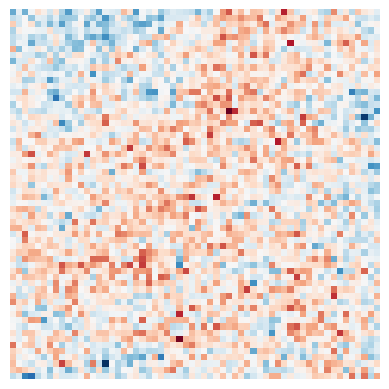

In [5]:
ra, dec = 300, 21
width = 30/60. #задается в градусах ширина рамки

# Build the box around the object and cut out a submap from the larger map
box = np.deg2rad([[dec-width/2.,ra-width/2.],[dec+width/2.,ra+width/2.]])

path = './'
map_path = path + 'act-planck_dr6.02_coadd_AA_daynight_f220_map.fits'
stamp = enmap.read_fits(map_path, box=box)[0] 

#Можно такэе сначала скачать всю карту 5 Гб
#imap= enmap.read_fits(map_path, box=box)[0] 
#Потом отрезок от нее часть !НО в таком подходе нельзя настроить размер изображения в пикселях
#stamp = imap.submap(box)

# Visualize the submap
plt.imshow(stamp, cmap = 'RdBu_r')
plt.axis('off')

### numpy

In [8]:
def pict(ra, dec, width=0.26668/2, plot=True):
    """
    Generate and display ACT (Atacama Cosmology Telescope) maps for three frequency bands.
    
    This function reads ACT survey data for 90GHz, 150GHz, and 220GHz frequency bands,
    crops to a specified region around given coordinates, and optionally displays the maps
    with source markers and aperture circles.
    
    Parameters
    ----------
    ra : float
        Right Ascension of the target position in degrees (J2000)
    dec : float 
        Declination of the target position in degrees (J2000)
    width : float, optional
        Width of the square region to extract in degrees. Default is 0.13334 degrees (8 arcminutes)
    plot : bool, optional
        If True, displays the maps. If False, returns the map arrays. Default is True.
    
    Returns
    -------
    tuple or None
        If plot=False, returns tuple of (imap_98, imap_150, imap_220) map arrays
        If plot=True, displays the maps and returns None
    
    Examples
    --------
    >>> # Display maps around RA=0°, Dec=0°
    >>> pict(0, 0)
    
    >>> # Get map data without plotting (for analysis)
    >>> maps_98, maps_150, maps_220 = pict(83.5, -5.5, plot=False)
    """
    #ACT crop
    box = np.deg2rad([[dec-width/2.,ra-width/2.],[dec+width/2.,ra+width/2.]])
    # устанавливаем pixbox
    pixbox = np.array([[0, 0,], [16,16]])

    imap_98 = enmap.read_map(path + 'act-planck_dr4dr6_coadd_AA_daynight_f090_map.fits', box=box, pixbox=pixbox)[0]
    imap_150 = np.array(enmap.read_map(path + 'act-planck_dr4dr6_coadd_AA_daynight_f150_map.fits', box=box, pixbox=pixbox)[0])
    imap_220 = np.array(enmap.read_map(path + 'act-planck_dr6.02_coadd_AA_daynight_f220_map.fits', box=box, pixbox=pixbox)[0])
    
    decs, ras = np.array(np.rad2deg(imap_98.posmap()))
    imap_98 = np.array(imap_98)
    
    ras=SkyCoord(ra=ras*u.degree, dec=decs*u.degree, frame='icrs').ra.degree    

    if plot:
        fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(8, 3))
        
        extent = [float(ras.max() + 0.5/2/60), float(ras.min() - 0.5/2/60), 
                  float(decs.min() - 0.5/2/60),  float(decs.max() + 0.5/2/60)]
        ax[0].imshow(imap_98, extent=extent)
        ax[1].imshow(imap_150, extent=extent)
        ax[2].imshow(imap_220, extent=extent)
        for i in range(3):
            ax[i].axis('off')
            ax[i].plot(ra, dec, 'x', ms=7, color='white')
            circle1 = plt.Circle((ra, dec), 30/3600,  fill=False, edgecolor='r', linewidth=1, linestyle='-')
            ax[i].add_artist(circle1)
            
        plt.show()
    else:
        return imap_98, imap_150, imap_220

In [9]:
pict(0.002440, 10.040771)

Форма массива: (3, 148, 148)


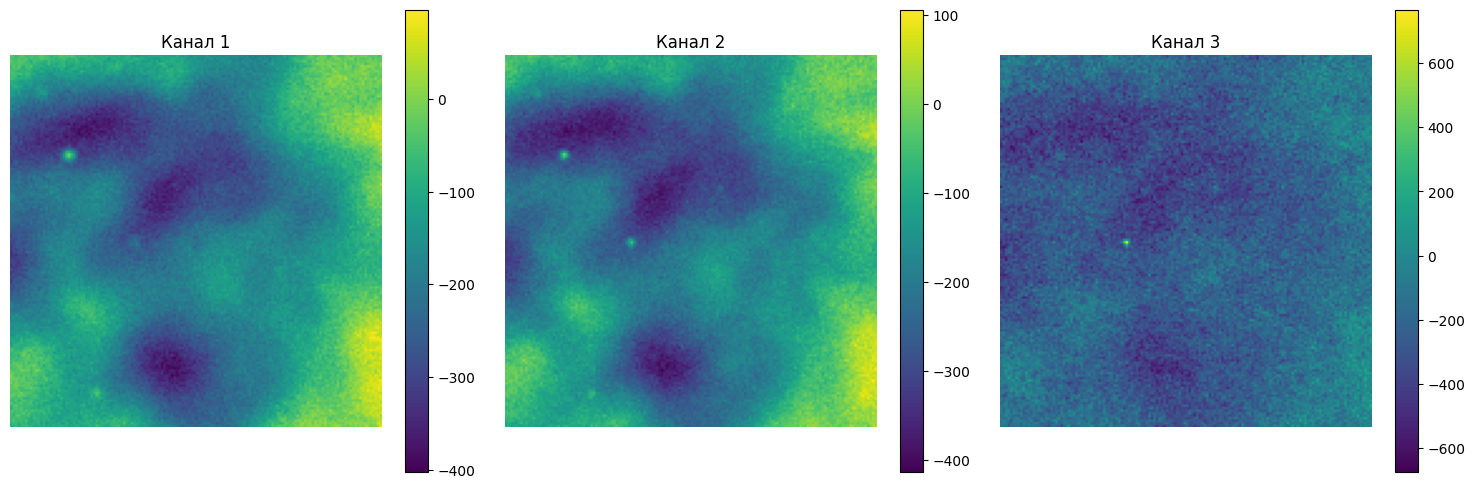

In [11]:
import numpy as np
import matplotlib.pyplot as plt

data = np.load(f'../dataset/images/{np.random.randint(8000)}.npy')

print("Форма массива:", data.shape)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i in range(3):
    im = axes[i].imshow(data[i], cmap='viridis')
    axes[i].set_title(f'Канал {i+1}')
    axes[i].axis('off')
    fig.colorbar(im, ax=axes[i])

plt.tight_layout()
plt.show()

5999
Форма массива: (3, 148, 148)


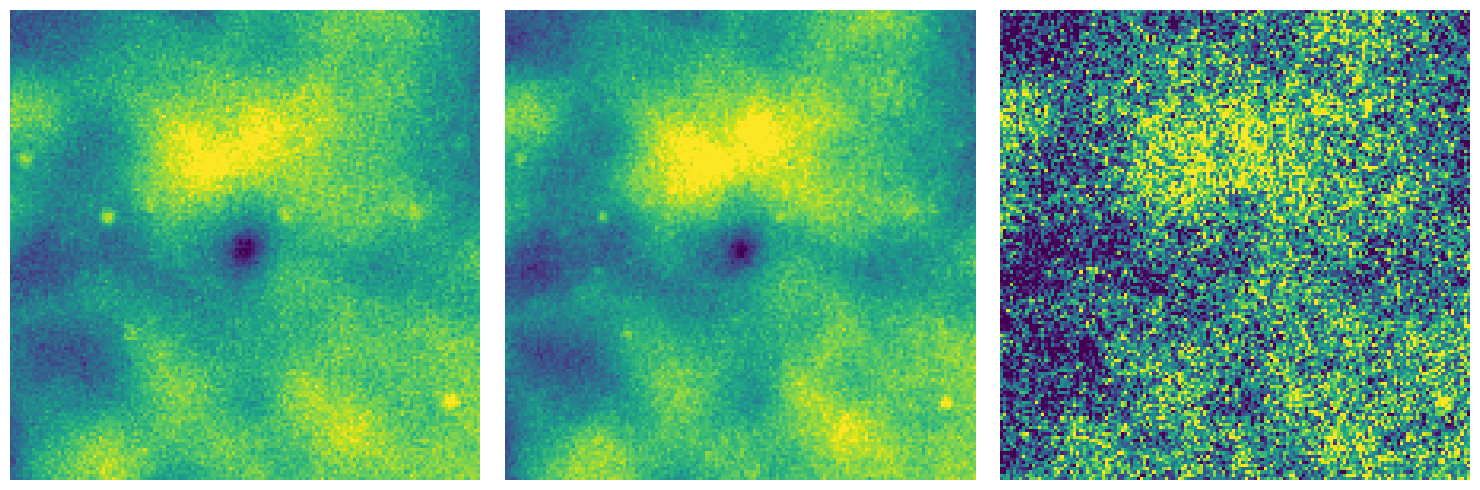

In [20]:
import numpy as np
import matplotlib.pyplot as plt
num = np.random.randint(9500)
print(num)
data = np.load(f'../dataset/images_normalized/{num}.npy')

print("Форма массива:", data.shape)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i in range(3):
    im = axes[i].imshow(data[i], cmap='viridis')
    axes[i].axis('off')

plt.tight_layout()
plt.show()

# Y-map

Карта Y, использованная в этом блокноте, представляет собой карту со следующими характеристиками:

- Отсутствие депроецируемых компонентов (вероятно, присутствует некоторое количество CIB и CMB-загрязнений)
- Эффективный beam 1,6'
- Пиксели 0,5'

## Download maps

In [ ]:
!wget https://lambda.gsfc.nasa.gov/data/suborbital/ACT/ACT_adv/Compton_y_maps/ilc_actplanck_ymap.fits
#маска
!wget https://lambda.gsfc.nasa.gov/data/suborbital/ACT/ACT_adv/Compton_y_maps/wide_mask_GAL070_apod_1.50_deg_wExtended.fits

## Plot maps

Посмотрите основную часть как отрисовывать карты выше, здесь лишь кусок для примера

In [28]:
path_y = './'
ymap = enmap.read_map(path_y + 'ilc_actplanck_ymap.fits')

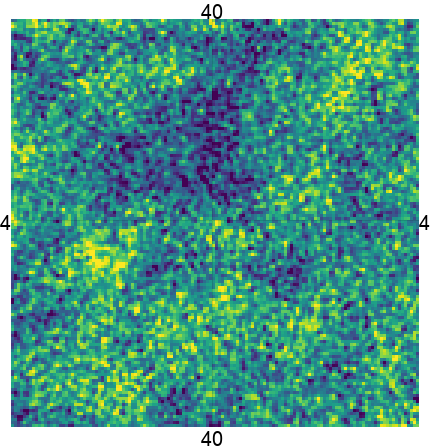

In [27]:
patch_size = 1.7*40/60
ra_center, dec_center = 40* utils.degree, 4* utils.degree
radius  = patch_size/2. * utils.degree
imap_sub = ymap.submap([[dec_center - radius, ra_center - radius], [dec_center + radius, ra_center + radius]])
eshow(imap_sub, upgrade=3, color='viridis')

Для того, чтобы работать в единой сетке вам нужно будет сделать депроекцию в HEALpix

In [29]:
hpm = reproject.map2healpix(ymap, nside=1024, lmax=6000, out=None,
                            rot=None, spin=[0,2], method="spline", order=0,
                            extensive=False, bsize=100000, nside_mode="pow2",
                            boundary="constant", verbose=False)

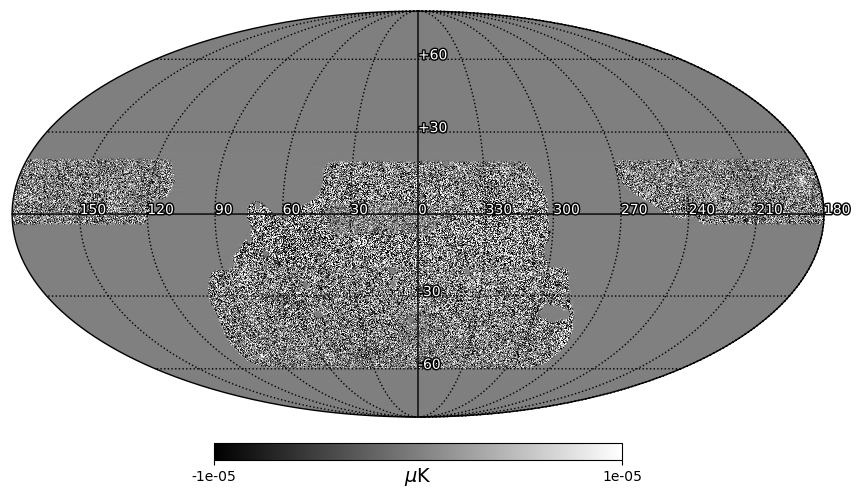

In [37]:
hp.visufunc.mollview(hpm,min=-1e-5, max=1e-5,cmap="gray",coord="C",
                 title="",unit=r"$\mu$K",notext=True,xsize=2000)

incolor = "white"
fgcolor = "black"
lw = 2

# Horizontal labels
lon_values = [0, 30, 60, 90, 120, 150, 180, 210, 240, 270, 300, 330]
for lon in lon_values:
    text_label = str(lon)
    hp.visufunc.projtext(lon, 0.0, text_label, lonlat=True, coord="C",
        color=incolor).set_path_effects([path_effects.Stroke(linewidth=lw,
        foreground=fgcolor),path_effects.Normal()])

# Vertical labels at lon=0
lat_values_0 = [30, 60, -30, -60]
for lat in lat_values_0:
    text_label = f"{'+' if lat > 0 else '-'}{abs(lat)}"
    hp.visufunc.projtext(0.0, lat, text_label, lonlat=True, coord="C",
        color=incolor).set_path_effects([path_effects.Stroke(linewidth=lw,
        foreground=fgcolor),path_effects.Normal()])

hp.graticule()

# Пример создания датасета

Лучше всего датасет хранить в формате [FITS](https://ru.wikipedia.org/wiki/FITS) — отраслевой стандарт, разработанный специально для научных данных. В отличие от обычных форматов изображений, FITS сохраняет не только пиксельные значения, но и полную астрономическую привязку (WCS), калибровочные коэффициенты, историю обработки и произвольные метаданные в структурированном заголовке

Напомню, что размер пикселя связан с угловыми минутами как 1 пиксель = 0.5 угловых минут

Таким образом, изображение радиусом в 8 угловых минут - 16 минут диаметр - 32 пикселя размер изображения (это если мы находимся в plat-caree проекции). Diffuse models надо переходить в healpy и там пересчитать размеры 

В массах тоже лучше перейти в healpy, чтобы не искажать форму скопления, но в принципе можете делать и в такой проекции

In [ ]:
width = 0.26668
for i in range(len(df)):
    ra, de = df.ra_deg[i], df.dec_deg[i]
    
    box = np.deg2rad([[de-width/2.,ra-width/2.],[de+width/2.,ra+width/2.]])
    pixbox = np.array([[0, 0,], [32, 32]])
    
    data90 = enmap.read_map(path + 'act-planck_dr4dr6_coadd_AA_daynight_f090_map.fits', box=box, pixbox=pixbox)[0]
    data150 = enmap.read_map(path + 'act-planck_dr4dr6_coadd_AA_daynight_f150_map.fits', box=box, pixbox=pixbox)[0]
    data220 = enmap.read_map(path + 'act-planck_dr6.02_coadd_AA_daynight_f220_map.fits', box=box, pixbox=pixbox)[0]
    
    # Сохранение в файл
    data = np.stack([np.array(data90), np.array(data150), np.array(data220)], axis=0)
    wcs_header = data90.wcs.to_header()
    hdul = fits.PrimaryHDU(data=data, header=wcs_header)
    #hdul.writeto(f'data/{i}.fits', overwrite=True)